# Урок 10. Нейроны, нейронная сеть и PyTorch

Датасет Iris: четыре признака цветка, три класса. Работа закрывает все три
уровня домашнего задания.

* **Лёгкий** — обучение при epochs 50, 100 и 200, сравнение loss и accuracy.
* **Средний** — три архитектуры сети и ответ на вопрос, всегда ли большая модель лучше.
* **Сильный** — сохранение модели и scaler, FastAPI-эндпоинт `POST /predict` (файл `api.py`).

> Файл `part2_pytorch_iris.py` с урока к заданию не приложен, поэтому пайплайн
> написан с нуля по описанию из методички: Iris, 4 признака, 3 класса,
> StandardScaler, CrossEntropyLoss, Adam.

In [1]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

pd.set_option("display.width", 120)
print("torch:", torch.__version__)

torch: 2.14.1+cpu


## Данные

In [2]:
iris = load_iris()
X, y = iris.data, iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["class"] = [iris.target_names[i] for i in y]
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),class
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("Размер:", X.shape)
print("Классы:", dict(zip(iris.target_names, np.bincount(y))))

Размер: (150, 4)
Классы: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}


### Разделение и масштабирование

Классы переводятся в числа, потому что модель работает только с числами.
Масштабирование нужно, чтобы признаки с разным размахом не доминировали при
обучении. Scaler обучается только на train.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("train:", X_train_tensor.shape, "| test:", X_test_tensor.shape)
print("dtype y:", y_train_tensor.dtype)

train: torch.Size([120, 4]) | test: torch.Size([30, 4])
dtype y: torch.int64


## Модель

В модели **нет Softmax**. Сеть возвращает logits — сырые числа без нормировки.
`CrossEntropyLoss` сам применяет log-softmax внутри, поэтому добавлять Softmax в
`forward` нельзя: это исказит градиенты. Softmax нужен только потом, когда
хочется показать вероятности человеку.

In [5]:
def build(sizes):
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(nn.ReLU())

    return nn.Sequential(*layers)


def train_model(sizes, epochs, lr=0.01, batch_size=16, seed=42):
    torch.manual_seed(seed)

    model = build(sizes)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor),
                        batch_size=batch_size, shuffle=True)

    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0

        for X_batch, y_batch in loader:
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total += loss.item() * len(X_batch)

        history.append(total / len(X_train_tensor))

    model.eval()
    with torch.no_grad():
        train_acc = accuracy_score(y_train, model(X_train_tensor).argmax(1).numpy())
        test_acc = accuracy_score(y_test, model(X_test_tensor).argmax(1).numpy())

    return model, history, train_acc, test_acc

Главный цикл обучения устроен так: `logits = model(X_batch)` — это **forward**,
`loss = loss_fn(...)` — расчёт ошибки, `loss.backward()` — **backward**, подсчёт
градиентов, `optimizer.step()` — шаг изменения весов. `zero_grad()` перед этим
обнуляет градиенты с прошлой итерации, иначе они накапливаются.

## Уровень 1. Сравнение количества эпох

In [6]:
ARCH = [4, 16, 8, 3]
epoch_runs = {}
rows = []

for epochs in (50, 100, 200):
    model, history, train_acc, test_acc = train_model(ARCH, epochs)
    epoch_runs[epochs] = history
    rows.append({
        "epochs": epochs,
        "final_loss": round(history[-1], 4),
        "train_accuracy": round(train_acc, 3),
        "test_accuracy": round(test_acc, 3),
    })

epochs_table = pd.DataFrame(rows)
epochs_table

,epochs,final_loss,train_accuracy,test_accuracy
0,50,0.0321,0.983,0.967
1,100,0.0182,0.992,0.967
2,200,0.0016,1.000,0.933


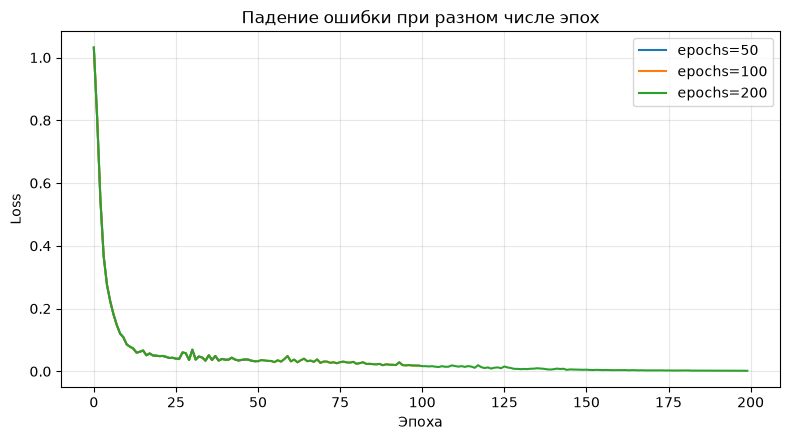

In [7]:
plt.figure(figsize=(8, 4.5))
for epochs, history in epoch_runs.items():
    plt.plot(history, label=f"epochs={epochs}")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Падение ошибки при разном числе эпох")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по уровню 1

Loss падает быстро в первые два-три десятка эпох, а затем выходит на плато.
Переход с 50 на 100 эпох ещё заметно уменьшает ошибку, а с 100 на 200 почти
ничего не меняет: модель уже нашла разделяющую поверхность, и дальнейшее
обучение лишь слегка подгоняет веса под обучающую выборку.

Accuracy на тесте при этом не просто перестаёт расти, а **падает**. При 50 и 100
эпохах точность на тесте одинаковая, а при 200 эпохах она снижается, хотя loss на
обучающей выборке стал почти нулевым и train accuracy достигла единицы.

Это учебный пример переобучения в чистом виде. Модель перестала искать общее
правило и начала запоминать конкретные обучающие цветы, включая их случайные
особенности. Главный вывод: меньше ошибка на train не означает лучше результат на
новых данных, и ориентироваться надо на тестовую метрику, а не на loss.

## Уровень 2. Сравнение архитектур

In [8]:
ARCHITECTURES = {
    "4-8-3": [4, 8, 3],
    "4-16-8-3": [4, 16, 8, 3],
    "4-32-16-8-3": [4, 32, 16, 8, 3],
}

rows = []
arch_runs = {}

for name, sizes in ARCHITECTURES.items():
    model, history, train_acc, test_acc = train_model(sizes, epochs=100)
    arch_runs[name] = history
    params = sum(p.numel() for p in model.parameters())
    rows.append({
        "architecture": name,
        "параметров": params,
        "final_loss": round(history[-1], 4),
        "train_accuracy": round(train_acc, 3),
        "test_accuracy": round(test_acc, 3),
    })

arch_table = pd.DataFrame(rows)
arch_table

,architecture,параметров,final_loss,train_accuracy,test_accuracy
0,4-8-3,67,0.0420,0.983,0.967
1,4-16-8-3,243,0.0182,0.992,0.967
2,4-32-16-8-3,851,0.0033,1.000,0.967


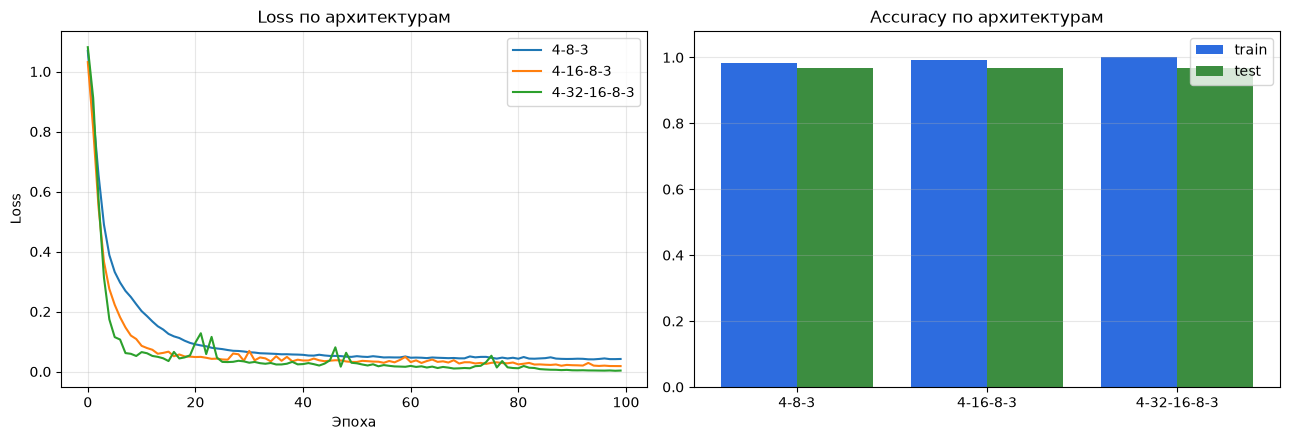

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, history in arch_runs.items():
    axes[0].plot(history, label=name)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss по архитектурам")
axes[0].legend()
axes[0].grid(alpha=0.3)

x = np.arange(len(arch_table))
axes[1].bar(x - 0.2, arch_table["train_accuracy"], 0.4, label="train", color="#2d6cdf")
axes[1].bar(x + 0.2, arch_table["test_accuracy"], 0.4, label="test", color="#3c8d40")
axes[1].set_xticks(x, arch_table["architecture"])
axes[1].set_ylim(0, 1.08)
axes[1].set_title("Accuracy по архитектурам")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Всегда ли большая модель лучше?

Нет. Таблица показывает это прямо: самая крупная сеть имеет на порядок больше
параметров, но на тестовой выборке не выигрывает у простой. Iris — лёгкая
задача: классы почти линейно разделимы, данных всего сто пятьдесят строк.
Сети из одного скрытого слоя для неё достаточно.

Лишние параметры дают модели возможность запоминать обучающие примеры вместо
поиска общего правила. На графике loss это видно: у большой сети ошибка на train
падает ниже, но на тест это не переносится. Размер модели должен соответствовать
сложности задачи и объёму данных, а не выбираться по принципу «чем больше, тем лучше».

## Финальная модель и пять предсказаний

In [10]:
final_model, history, train_acc, test_acc = train_model([4, 16, 8, 3], epochs=100)
print(f"train accuracy: {train_acc:.3f}")
print(f"test accuracy:  {test_acc:.3f}")

with torch.no_grad():
    logits = final_model(X_test_tensor)
    probabilities = torch.softmax(logits, dim=1)
    predicted = logits.argmax(1).numpy()

cm = confusion_matrix(y_test, predicted)
print("\nConfusion matrix:")
print(pd.DataFrame(cm, index=iris.target_names, columns=iris.target_names).to_string())

train accuracy: 0.992
test accuracy:  0.967

Confusion matrix:
            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           0         10


Первые пять объектов тестовой выборки: logits, вероятности после softmax и
сравнение предсказанного класса с настоящим.

In [11]:
rows = []
for i in range(5):
    rows.append({
        "logits": np.round(logits[i].numpy(), 2).tolist(),
        "probabilities": np.round(probabilities[i].numpy(), 3).tolist(),
        "predicted": iris.target_names[predicted[i]],
        "real": iris.target_names[y_test[i]],
        "совпало": "да" if predicted[i] == y_test[i] else "нет",
    })

pd.DataFrame(rows)

,logits,probabilities,predicted,real,совпало
0,"[8.06, -3.41, -20.0]","[1.0, 0.0, 0.0]",setosa,setosa,да
1,"[-6.66, 0.92, 3.2]","[0.0, 0.093, 0.907]",virginica,virginica,да
2,"[-2.37, 5.18, -3.44]","[0.001, 0.999, 0.0]",versicolor,versicolor,да
3,"[-2.73, 5.56, -3.38]","[0.0, 1.0, 0.0]",versicolor,versicolor,да
4,"[8.97, -3.53, -22.49]","[1.0, 0.0, 0.0]",setosa,setosa,да


## Сохранение модели и scaler для API

In [12]:
torch.save({
    "state_dict": final_model.state_dict(),
    "architecture": [4, 16, 8, 3],
    "classes": iris.target_names.tolist(),
    "features": iris.feature_names,
}, "model.pt")

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Сохранено: model.pt, scaler.pkl")
print("Запуск API: uvicorn api:app --reload")

Сохранено: model.pt, scaler.pkl
Запуск API: uvicorn api:app --reload
